# 01 — EDA & vérification du test randomisé

**Question business** : à qui envoyer un email (Hommes / Femmes) pour maximiser le profit incrémental ?

**Questions de recherche**
1. Les groupes traités et contrôle sont-ils comparables ? (sans randomisation, pas d'inférence causale simple)
2. Quel est l'effet moyen (ATE) de chaque email sur la conversion ? Est-il significatif ?
3. L'effet est-il **hétérogène** selon les clients ? (sinon l'uplift modeling n'apporte rien)
4. Quelles contraintes impose un événement aussi rare que la conversion ?

> Si `data/raw/hillstrom.csv` est absent, `load_raw` le télécharge (ou `UPLIFT_SYNTHETIC=1` pour des données de test).

In [5]:
import sys, warnings
sys.path.insert(0, "../src")            # pas d'installation nécessaire
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import load_config

cfg = load_config()
ARMS, CTRL = cfg["arms"], cfg["control_label"]
pd.set_option("display.float_format", lambda v: f"{v:.5f}")

from data import load_raw, prepare, FEATURES, NUM, BIN, CAT

raw, source = load_raw(cfg)
df = prepare(raw, cfg)
print("source:", source, "| shape:", df.shape)
df.head()


source: hillstrom | shape: (64000, 9)


,recency,history,mens,womens,newbie,zip_code,channel,treatment,y
0,10,142.44000,1,0,0,Surburban,Phone,Womens E-Mail,0
1,6,329.08000,1,1,1,Rural,Web,No E-Mail,0
2,7,180.65000,0,1,1,Surburban,Web,Womens E-Mail,0
3,9,675.83000,1,0,1,Rural,Web,Mens E-Mail,0
4,2,45.34000,1,0,0,Urban,Web,Womens E-Mail,0


In [9]:
df.dtypes.to_frame('dtype').join(df.isna().sum().rename('missing')).join(df.duplicated().rename('duplicates')).T

,recency,history,mens,womens,newbie,zip_code,channel,treatment,y
dtype,int64,float64,int64,int64,int64,str,str,str,int64
missing,0,0,0,0,0,0,0,0,0
duplicates,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Taux de conversion par groupe et effet moyen (ATE)

Analyse A/B : effet de chaque traitement vs contrôle

**Objectif** : mesurer, pour chaque bras de traitement, l'effet sur le taux de conversion (`y` ∈ {0, 1}) par rapport au groupe contrôle, et savoir si cet effet est statistiquement significatif.

### 1. Résumé par groupe
Pour chaque groupe : effectif $n$, nombre de conversions $x = \sum y_i$ et taux de conversion $\hat p = x / n$.

### 2. Comparaison de chaque bras $a$ au contrôle $c$

| Métrique | Formule | Interprétation |
|---|---|---|
| **ATE** (effet moyen) | $\hat p_a - \hat p_c$ | Gain absolu en points de conversion |
| **Erreur standard** | $SE = \sqrt{\dfrac{s_a^2}{n_a} + \dfrac{s_c^2}{n_c}}$ | Incertitude sur l'ATE (non poolée) |
| **IC 95 %** | $ATE \pm 1{,}96 \times SE$ | Si 0 n'est pas dans l'intervalle, l'effet est significatif |
| **Lift relatif** | $\dfrac{\hat p_a - \hat p_c}{\hat p_c}$ | Gain en % par rapport au contrôle |
| **p-value** | test z de 2 proportions | Probabilité d'observer un tel écart si $H_0$ est vraie |

**Test z de deux proportions** :

- $H_0 : p_a = p_c$ contre $H_1 : p_a \neq p_c$
- $z = \dfrac{\hat p_a - \hat p_c}{\sqrt{\hat p (1-\hat p)\left(\frac{1}{n_a}+\frac{1}{n_c}\right)}}$ avec $\hat p = \dfrac{x_a + x_c}{n_a + n_c}$ (variance poolée sous $H_0$)
- $p = 2\,(1 - \Phi(|z|))$

### 3. Sortie
Un tableau avec une ligne par bras : `ate`, `ci_low`, `ci_high`, `rel_lift`, `p_value`.

### ⚠️ Limites
- **Comparaisons multiples** : plusieurs bras augmentent le risque de faux positifs → corriger les p-values (Bonferroni, Holm, Benjamini-Hochberg).
- **Approximation normale** : valide si $n\hat p$ et $n(1-\hat p)$ sont suffisamment grands (> 10 environ).
- **Lift relatif** : pas d'IC fourni (il faudrait la méthode delta ou un bootstrap).
- L'IC (SE non poolée) et le test z (SE poolée) peuvent légèrement diverger près du seuil.

In [ ]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05

# 1. Résumé par groupe
g = (df.groupby("treatment").y
       .agg(["size", "sum", "mean"])
       .rename(columns={"size": "n", "sum": "conversions", "mean": "conv_rate"}))
display(g)

# 2. Comparaison de chaque bras vs contrôle
c = df[df.treatment == CTRL].y
n_c, x_c, p_c = len(c), c.sum(), c.mean()

rows = []
for a in ARMS:
    t = df[df.treatment == a].y
    n_a, x_a, p_a = len(t), t.sum(), t.mean()

    # ATE + IC 95 % (SE non poolée)
    d = p_a - p_c
    se = np.sqrt(t.var(ddof=1) / n_a + c.var(ddof=1) / n_c)

    # Test z de 2 proportions (variance poolée)
    z, p = proportions_ztest([x_a, x_c], [n_a, n_c])

    # Lift relatif + IC (méthode delta sur log du ratio)
    ratio = p_a / p_c
    se_log = np.sqrt((1 - p_a) / (n_a * p_a) + (1 - p_c) / (n_c * p_c))
    lift_low = ratio * np.exp(-1.96 * se_log) - 1
    lift_high = ratio * np.exp(+1.96 * se_log) - 1

    # Validité de l'approximation normale (n*p et n*(1-p) >= 10)
    normal_ok = min(n_a * p_a, n_a * (1 - p_a), n_c * p_c, n_c * (1 - p_c)) >= 10

    rows.append(dict(
        arm=a, n=n_a, conv_rate=p_a,
        ate=d, ci_low=d - 1.96 * se, ci_high=d + 1.96 * se,
        rel_lift=d / p_c, lift_ci_low=lift_low, lift_ci_high=lift_high,
        z=z, p_value=p, normal_ok=normal_ok,
    ))

res = pd.DataFrame(rows).set_index("arm")

# 3. Correction des comparaisons multiples
res["p_holm"] = multipletests(res["p_value"], alpha=ALPHA, method="holm")[1]
res["p_bonf"] = multipletests(res["p_value"], alpha=ALPHA, method="bonferroni")[1]

# 4. Verdict (basé sur Holm, plus puissant que Bonferroni)
res["significant"] = res["p_holm"] < ALPHA

res.round(4)

,n,conversions,conv_rate
treatment,,,
Mens E-Mail,21307,267,0.01253
No E-Mail,21306,122,0.00573
Womens E-Mail,21387,189,0.00884


,n,conv_rate,ate,ci_low,ci_high,rel_lift,lift_ci_low,lift_ci_high,z,p_value,normal_ok,p_holm,p_bonf,significant
arm,,,,,,,,,,,,,,
Mens E-Mail,21307,0.01250,0.00680,0.00500,0.00860,1.18840,0.76800,1.70890,7.38510,0.00000,True,0.00000,0.00000,True
Womens E-Mail,21387,0.00880,0.00310,0.00150,0.00470,0.54330,0.23010,0.93630,3.77960,0.00020,True,0.00020,0.00030,True



**Mens E-Mail**
- La conversion passe de 0,57 % à 1,25 %, soit **+0,68 point** (IC 95 % : +0,50 à +0,86 pt), donc plus que le double (**+119 %**, IC : +77 % à +171 %).
- L'IC de l'ATE est strictement positif et $z = 7{,}4$ : effet très significatif, p-value ajustée quasi nulle.
- Même dans le pire scénario de l'IC, le gain reste important.

**Womens E-Mail**
- La conversion passe de 0,57 % à 0,88 %, soit **+0,31 point** (IC 95 % : +0,15 à +0,47 pt), donc **+54 %** (IC : +23 % à +94 %).
- $z = 3{,}8$ et p ajustée ≈ 0,0002 : effet significatif, mais plus faible et plus incertain que Mens (IC relatif large).

**Comparaison et robustesse**
- **Mens > Womens** : les IC de l'ATE ne se chevauchent pas, ce qui suggère que Mens est meilleur. Non testé directement : un test z entre les deux bras serait à ajouter.
- **Correction des comparaisons multiples** (Holm, Bonferroni) : aucun verdict ne change, la conclusion est robuste.
- **Approximation normale valide** (`normal_ok = True`) : effectifs de conversions suffisants (122 dans le contrôle).

**Réserves**
- **Taux très faibles** : un lift de +119 % correspond à moins d'un point de conversion en plus. Toujours reporter l'ATE absolu avec le lift relatif.
- **Significatif ≠ rentable** : comparer les conversions supplémentaires (× valeur) au coût d'envoi.
- **Validité causale** : suppose une assignation réellement aléatoire (à vérifier par un test d'équilibre des covariables).
- **Effet moyen uniquement** : l'ATE masque l'hétérogénéité, d'où l'intérêt d'un **uplift modeling** pour cibler les profils les plus réceptifs.

**Conclusion**
> Les deux emails augmentent significativement la conversion vs l'absence d'email (p < 0,001 après correction de Holm). Mens est le plus efficace (+0,68 pt, +119 %) contre +0,31 pt (+54 %) pour Womens. Il reste à valider la rentabilité et à explorer le ciblage par segments.

## 2. La randomisation tient-elle ?
Deux contrôles : (a) différences standardisées des moyennes (SMD, seuil usuel |SMD| < 0.1) ; (b) un classifieur ne doit **pas** pouvoir prédire le groupe à partir des features (AUC ≈ 0.5).

In [18]:
from features import build_preprocessor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
X = pd.get_dummies(df[FEATURES], columns=CAT, dtype=float)
smd = {}
for a in ARMS:
    m = df.treatment == a; k = df.treatment == CTRL
    smd[a] = (X[m].mean() - X[k].mean()) / np.sqrt((X[m].var() + X[k].var()) / 2)
smd = pd.DataFrame(smd); display(smd.round(4))
print("max |SMD| :", float(smd.abs().max().max()))
Z = build_preprocessor().fit_transform(df[FEATURES])
for a in ARMS:
    mask = df.treatment.isin([a, CTRL]).to_numpy()
    auc = cross_val_score(LogisticRegression(max_iter=1000), Z[mask], (df.treatment[mask] == a).astype(int), cv=5, scoring="roc_auc").mean()
    print(f"AUC prédire '{a}' vs contrôle : {auc:.3f}  (≈0.5 attendu)")

,Mens E-Mail,Womens E-Mail
recency,0.00680,0.00520
history,0.00760,0.00650
mens,-0.00460,-0.00860
womens,0.00760,0.00490
newbie,-0.00090,0.00260
zip_code_Rural,0.01370,0.00400
zip_code_Surburban,-0.01170,-0.00110
zip_code_Urban,0.00200,-0.00180
channel_Multichannel,-0.00420,-0.00530
channel_Phone,-0.00830,0.00860


max |SMD| : 0.01365900039927897
AUC prédire 'Mens E-Mail' vs contrôle : 0.496  (≈0.5 attendu)
AUC prédire 'Womens E-Mail' vs contrôle : 0.496  (≈0.5 attendu)


**Conclusion** : les trois groupes sont équilibrés sur toutes les features observées. L'assignation se comporte comme une vraie randomisation, ce qui valide la lecture causale de l'ATE.

### Contrôle 1 : différences standardisées (SMD)
- Le **|SMD| maximum est de 0,014**, soit environ 7 fois sous le seuil usuel de 0,1.
- L'équilibre est bon pour les deux bras, sur les variables numériques (`recency`, `history`) comme sur les variables catégorielles (`zip_code`, `channel`, `newbie`, `mens`, `womens`).
- Les écarts sont de signes variés (positifs et négatifs) et sans structure : c'est le bruit d'échantillonnage attendu, pas un biais systématique.

### Contrôle 2 : classifieur de groupe
- L'**AUC est de 0,496** pour les deux bras, soit ≈ 0,5 : les features ne permettent pas de deviner si un client a reçu l'email ou non.
- Une AUC légèrement sous 0,5 n'a pas de sens particulier : c'est du bruit autour du hasard.
- Ce test complète le SMD : il vérifie l'équilibre **conjoint** des variables (interactions comprises), là où le SMD regarde chaque variable séparément.

### Ce que ça implique
- Les différences de conversion observées (ATE) ne s'expliquent pas par des profils clients différents entre groupes.
- Pas besoin d'ajuster sur les covariables pour corriger un déséquilibre (un ajustement resterait possible pour gagner en précision).

### Limites
- Le contrôle ne porte que sur les **variables observées** : il ne prouve pas l'absence de déséquilibre sur des variables non mesurées (c'est le rôle de la randomisation elle-même).
- La régression logistique ne capte que des relations **linéaires** : un classifieur non linéaire (gradient boosting) renforcerait le test.
- Avec ~21 000 clients par groupe, le test est très sensible : trouver des écarts aussi faibles est un bon signe.

## 3. Événement rare : conséquences

In [19]:
print(f"taux de conversion global : {df.y.mean():.4%}")
print("conversions par groupe :", df.groupby("treatment").y.sum().to_dict())

taux de conversion global : 0.9031%
conversions par groupe : {'Mens E-Mail': 267, 'No E-Mail': 122, 'Womens E-Mail': 189}


Avec un taux de conversion inférieur au pourcent (0,90 %), le signal est faible et bruité. Conséquences retenues pour la suite :

- split **stratifié sur (traitement × conversion)** (`data.split`) ;
- modèles **régularisés** (arbres peu profonds, `min_samples_leaf` élevé) ;
- sélection du learner sur un jeu de **validation**, jamais sur le test ;
- évaluation par courbe de **Qini** (pas de vérité terrain individuelle observable), avec **IC par bootstrap** vu le faible nombre de conversions ;
- **tests statistiques appropriés** (test z de 2 proportions, correction de Holm) et analyse de puissance ;
- pas de rééquilibrage artificiel des classes (SMOTE, sous-échantillonnage), qui fausserait l'estimation de l'effet.

## 4. Hétérogénéité de l'effet : y a-t-il quelque chose à cibler ?

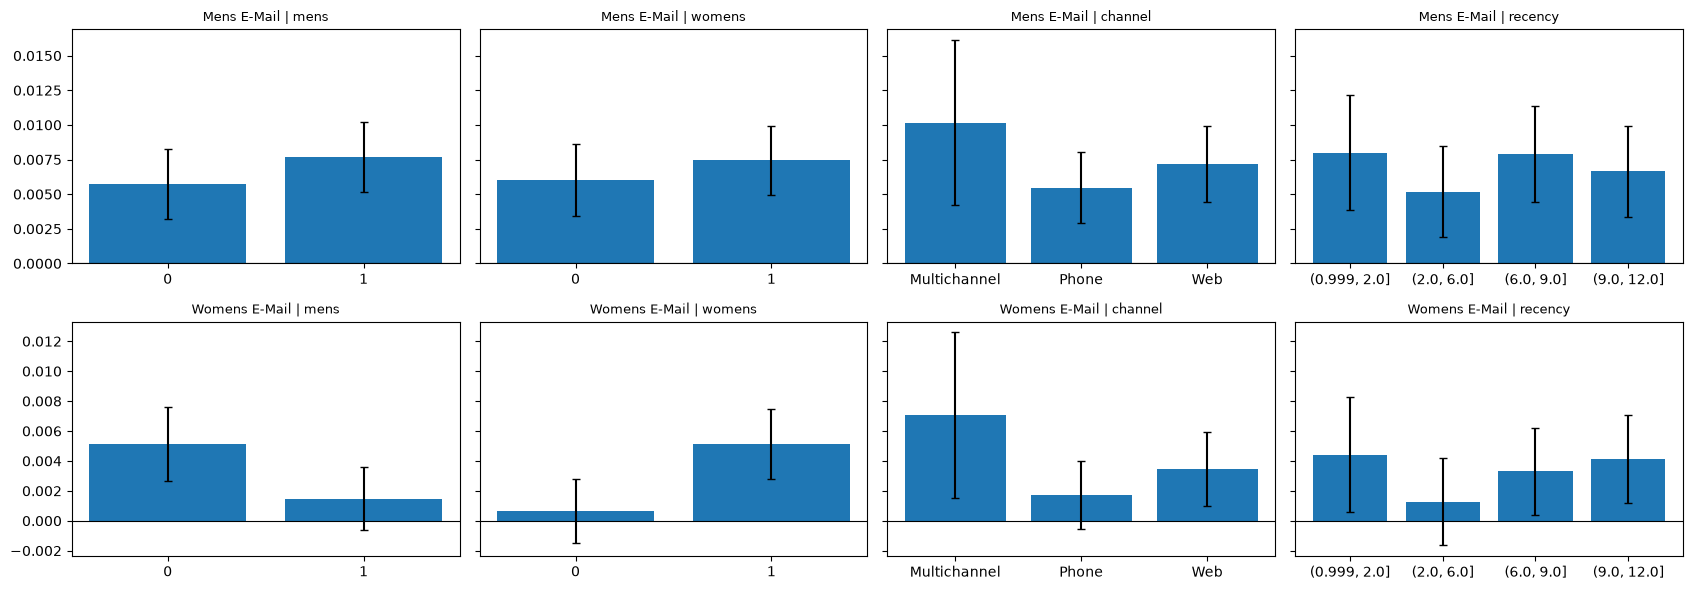

In [20]:
def uplift_by(col, arm, bins=None):
    s = pd.qcut(df[col], bins, duplicates="drop") if bins else df[col]
    out = []
    for lvl, d in df[df.treatment.isin([arm, CTRL])].groupby(s[df.treatment.isin([arm, CTRL])], observed=True):
        t, k = d[d.treatment == arm].y, d[d.treatment == CTRL].y
        se = np.sqrt(t.var(ddof=1)/len(t) + k.var(ddof=1)/len(k))
        out.append(dict(level=str(lvl), uplift=t.mean()-k.mean(), se=se, n=len(d)))
    return pd.DataFrame(out)

fig, axes = plt.subplots(len(ARMS), 4, figsize=(17, 6), sharey="row")
for r, arm in enumerate(ARMS):
    for c_, (col, bins) in enumerate([("mens", None), ("womens", None), ("channel", None), ("recency", 4)]):
        u = uplift_by(col, arm, bins)
        axes[r, c_].bar(u.level, u.uplift, yerr=1.96*u.se, capsize=3)
        axes[r, c_].axhline(0, color="k", lw=.8); axes[r, c_].set_title(f"{arm} | {col}", fontsize=9)
plt.tight_layout(); plt.show()

**Conclusion** : l'effet est **positif dans presque tous les sous-groupes** pour Mens, sans hétérogénéité nette. Pour Womens, une piste ressort (clientes ayant acheté des produits femmes), mais le bruit reste important.

### Mens E-Mail
- **Tous les IC sont au-dessus de 0** (uplift entre ≈ +0,5 et +1,0 pt) : l'email marche partout.
- Les barres sont **très proches** et leurs IC se chevauchent largement : pas de segment qui se démarque clairement.
- `channel` : Multichannel paraît le plus élevé (≈ +1,0 pt), mais avec un IC très large (peu de clients), donc non concluant.
- `recency` : aucune tendance monotone (pas de « plus récent = plus réceptif »).

### Womens E-Mail
- `womens` : uplift d'environ **+0,5 pt chez les clientes ayant acheté des produits femmes (`womens = 1`)** contre ≈ 0 pour `womens = 0` (IC qui contient 0). L'effet semble concentré sur la cible naturelle de l'email, ce qui est cohérent métier.
- `mens` : uplift plus faible pour `mens = 1` (IC qui contient 0). Les deux variables ne sont pas exclusives (un client peut avoir acheté les deux), donc les deux graphiques ne sont pas de simples miroirs.
- `channel` : Multichannel en tête mais IC très large ; Phone proche de 0.
- `recency` : le segment (2, 6] est proche de 0, sans logique d'ensemble.

### Ce que ça implique
- Un **ciblage simple** « Womens email uniquement aux clientes `womens = 1` » est une piste plausible.
- Pour Mens, le gain d'un ciblage fin semble **limité** : envoyer à tous reste défendable si le coût d'envoi est faible.
- Cela justifie de tester un **modèle d'uplift** (section suivante), avec des attentes modestes.

### Limites
- **Analyse exploratoire** : une dizaine de sous-groupes par bras, IC non corrigés pour les comparaisons multiples. Un écart isolé peut être du bruit.
- **IC qui se chevauchent ≠ test d'interaction** : pour affirmer qu'un segment diffère vraiment, il faut tester l'interaction traitement × variable (régression logistique avec terme croisé).
- **Peu de conversions par segment** (122 dans le contrôle au total, réparties entre les modalités) : d'où les IC larges.
- **Une variable à la fois** : on peut manquer des effets d'interaction entre variables (par exemple `womens` × `channel`).
- Axes en **points absolus** : lire les échelles par ligne (`sharey="row"`), pas entre les deux lignes.

## Décisions pour la modélisation

- **ATE positif pour les deux bras**, mais **hétérogénéité peu marquée** : les IC se recouvrent presque partout, seule une piste ressort (Womens plus efficace chez `womens = 1`). L'intérêt de l'uplift modeling n'est donc **pas acquis**, il est à valider sur le jeu de test (courbe de Qini, comparée à un envoi à tous et à un ciblage aléatoire).
- Le ciblage se justifie surtout par le **coût d'envoi et le budget** : même avec un uplift positif partout, on peut ne contacter que les clients dont le gain attendu dépasse le coût.
- Deux traitements → on estime l'uplift **par bras vs contrôle** (`MultiArmUplift`), puis on choisit **le meilleur bras par client**, ou **aucun email** si le gain net est négatif. Les estimations étant bruitées, le « meilleur bras » risque d'être surestimé : à vérifier sur données hors échantillon.
- Test d'interaction (traitement × variable) à ajouter pour confirmer les segments suspectés.
- Suite : `02_modeling_prototype.ipynb`.